In [1]:
import pandas as pd
import numpy as np

# Load the original rainfall dataset
df = pd.read_csv(
    "../data/raw/kerala_rainfall_1901_2017.csv"
)

# Display the first five rows
df.head()

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,Kerala,1901,28.7,44.7,51.6,160.0,174.7,824.6,743.0,357.5,197.7,266.9,350.8,48.4,3248.6,73.4,386.2,2122.8,666.1
1,Kerala,1902,6.7,2.6,57.3,83.9,134.5,390.9,1205.0,315.8,491.6,358.4,158.3,121.5,3326.6,9.3,275.7,2403.4,638.2
2,Kerala,1903,3.2,18.6,3.1,83.6,249.7,558.6,1022.5,420.2,341.8,354.1,157.0,59.0,3271.2,21.7,336.3,2343.0,570.1
3,Kerala,1904,23.7,3.0,32.2,71.5,235.7,1098.2,725.5,351.8,222.7,328.1,33.9,3.3,3129.7,26.7,339.4,2398.2,365.3
4,Kerala,1905,1.2,22.3,9.4,105.9,263.3,850.2,520.5,293.6,217.2,383.5,74.4,0.2,2741.6,23.4,378.5,1881.5,458.1


In [2]:
# Check dataset dimensions
print("Dataset dimensions:", df.shape)

# Check number of observations
print("Number of observations:", df.shape[0])

# Check number of features
print("Number of columns:", df.shape[1])

Dataset dimensions: (117, 19)
Number of observations: 117
Number of columns: 19


In [3]:
# Display all column names
print(df.columns.tolist())

['SUBDIVISION', 'YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'JF', 'MAM', 'JJAS', 'OND']


In [4]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SUBDIVISION  117 non-null    str    
 1   YEAR         117 non-null    int64  
 2   JAN          117 non-null    float64
 3   FEB          117 non-null    float64
 4   MAR          117 non-null    float64
 5   APR          117 non-null    float64
 6   MAY          117 non-null    float64
 7   JUN          117 non-null    float64
 8   JUL          117 non-null    float64
 9   AUG          117 non-null    float64
 10  SEP          117 non-null    float64
 11  OCT          117 non-null    float64
 12  NOV          117 non-null    float64
 13  DEC          117 non-null    float64
 14  ANNUAL       117 non-null    float64
 15  JF           117 non-null    float64
 16  MAM          117 non-null    float64
 17  JJAS         117 non-null    float64
 18  OND          117 non-null    float64
dtypes: float64(17), int

In [5]:
# Generate descriptive statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
YEAR,117.0,1959.000000,33.919021,1901.0,1930.0,1959.0,1988.0,2017.0
JAN,117.0,12.171795,15.428164,0.0,2.4,6.0,16.9,83.5
FEB,117.0,15.374359,16.127841,0.0,4.7,8.4,21.4,79.0
MAR,117.0,37.127350,30.460281,0.1,18.1,28.3,50.1,217.2
APR,117.0,109.419658,45.169247,13.1,71.5,108.4,135.1,238.0
MAY,117.0,229.983761,148.010937,53.4,124.5,190.6,265.4,738.8
JUN,117.0,653.164957,186.222721,196.8,541.7,625.8,788.5,1098.2
JUL,117.0,695.979487,226.570097,167.5,532.0,687.3,831.6,1526.5
AUG,117.0,420.692308,159.340480,178.6,315.3,385.2,495.0,1199.2
SEP,117.0,245.861538,123.265815,41.3,150.1,223.9,335.6,526.7


In [6]:
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check duplicate years
print("Duplicate years:", df["YEAR"].duplicated().sum())

# Check unique subdivisions
print("Unique subdivisions:", df["SUBDIVISION"].nunique())

Missing values:
SUBDIVISION    0
YEAR           0
JAN            0
FEB            0
MAR            0
APR            0
MAY            0
JUN            0
JUL            0
AUG            0
SEP            0
OCT            0
NOV            0
DEC            0
ANNUAL         0
JF             0
MAM            0
JJAS           0
OND            0
dtype: int64

Duplicate rows: 0
Duplicate years: 0
Unique subdivisions: 1


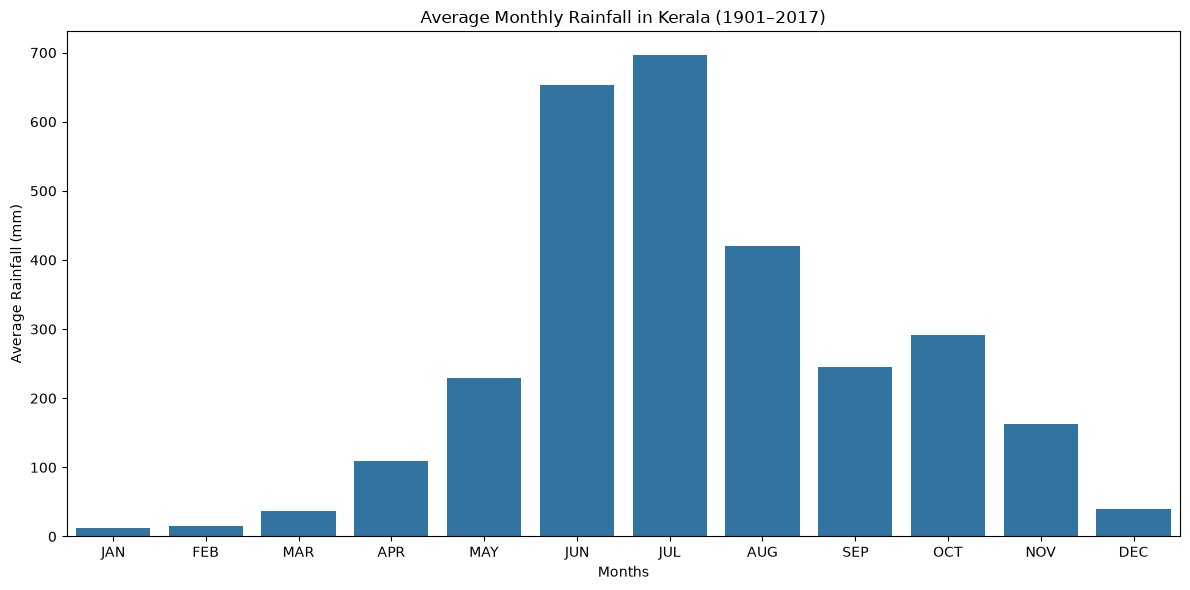

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select monthly rainfall columns
months = [
    "JAN", "FEB", "MAR", "APR",
    "MAY", "JUN", "JUL", "AUG",
    "SEP", "OCT", "NOV", "DEC"
]

# Calculate average rainfall for each month
monthly_avg = df[months].mean()

# Create the bar graph
plt.figure(figsize=(12, 6))

sns.barplot(
    x=monthly_avg.index,
    y=monthly_avg.values
)

# Add graph labels and title
plt.title("Average Monthly Rainfall in Kerala (1901–2017)")
plt.xlabel("Months")
plt.ylabel("Average Rainfall (mm)")

plt.tight_layout()

# Save the graph
plt.savefig("../figures/01_monthly_average_rainfall.png", dpi=300)

# Display the graph
plt.show()

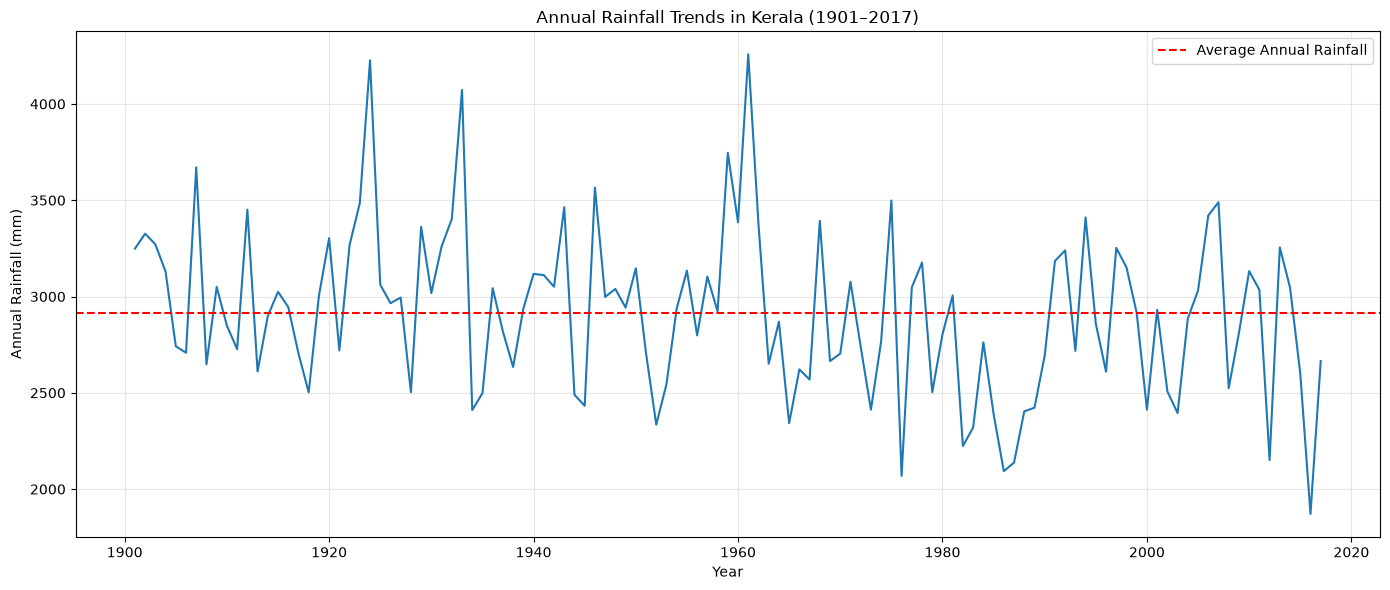

In [8]:
# Sort dataset according to year
annual_df = df.sort_values("YEAR")

# Create figure
plt.figure(figsize=(14, 6))

# Plot annual rainfall
sns.lineplot(
    data=annual_df,
    x="YEAR",
    y="ANNUAL"
)

# Calculate overall average rainfall
average_rainfall = df["ANNUAL"].mean()

# Add average rainfall reference line
plt.axhline(
    y=average_rainfall,
    color="red",
    linestyle="--",
    label="Average Annual Rainfall"
)

# Add title and labels
plt.title("Annual Rainfall Trends in Kerala (1901–2017)")
plt.xlabel("Year")
plt.ylabel("Annual Rainfall (mm)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save graph
plt.savefig(
    "../figures/02_annual_rainfall_trend.png",
    dpi=300
)

# Display graph
plt.show()

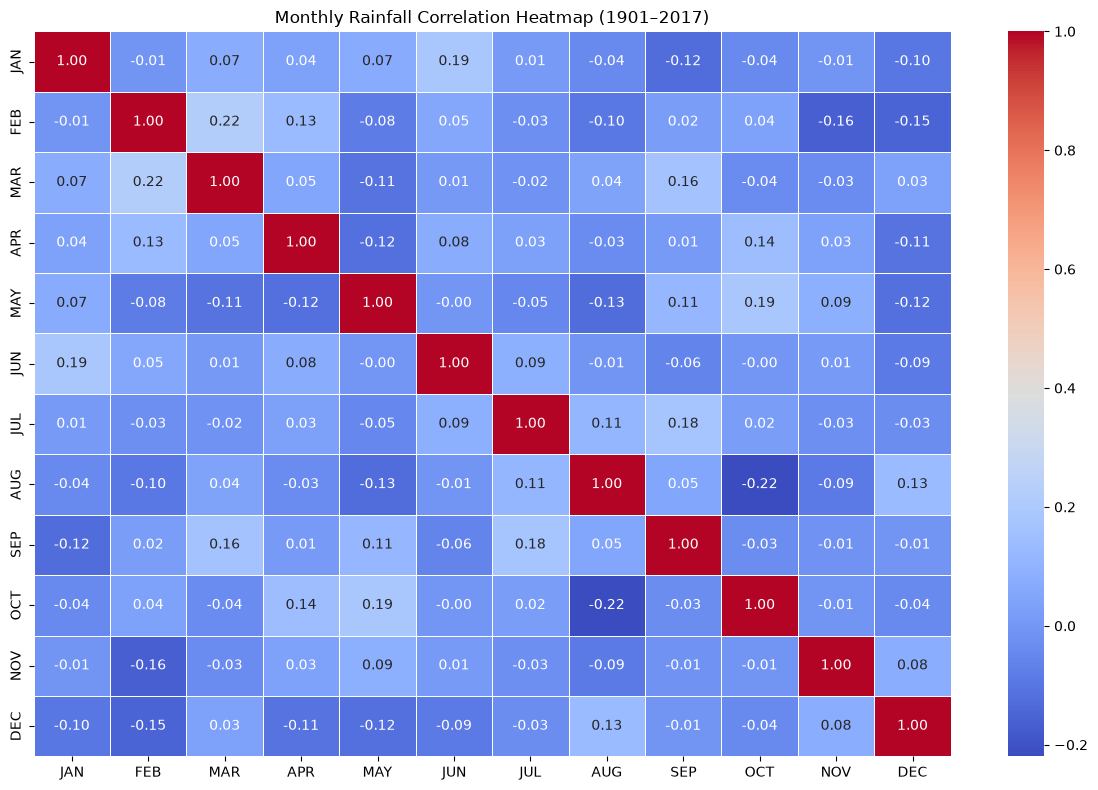

In [9]:
# Select monthly rainfall columns
monthly_data = df[months]

# Calculate correlation between months
correlation_matrix = monthly_data.corr()

# Create heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

# Add title
plt.title("Monthly Rainfall Correlation Heatmap (1901–2017)")

plt.tight_layout()

# Save figure
plt.savefig(
    "../figures/03_monthly_rainfall_correlation.png",
    dpi=300
)

# Display
plt.show()

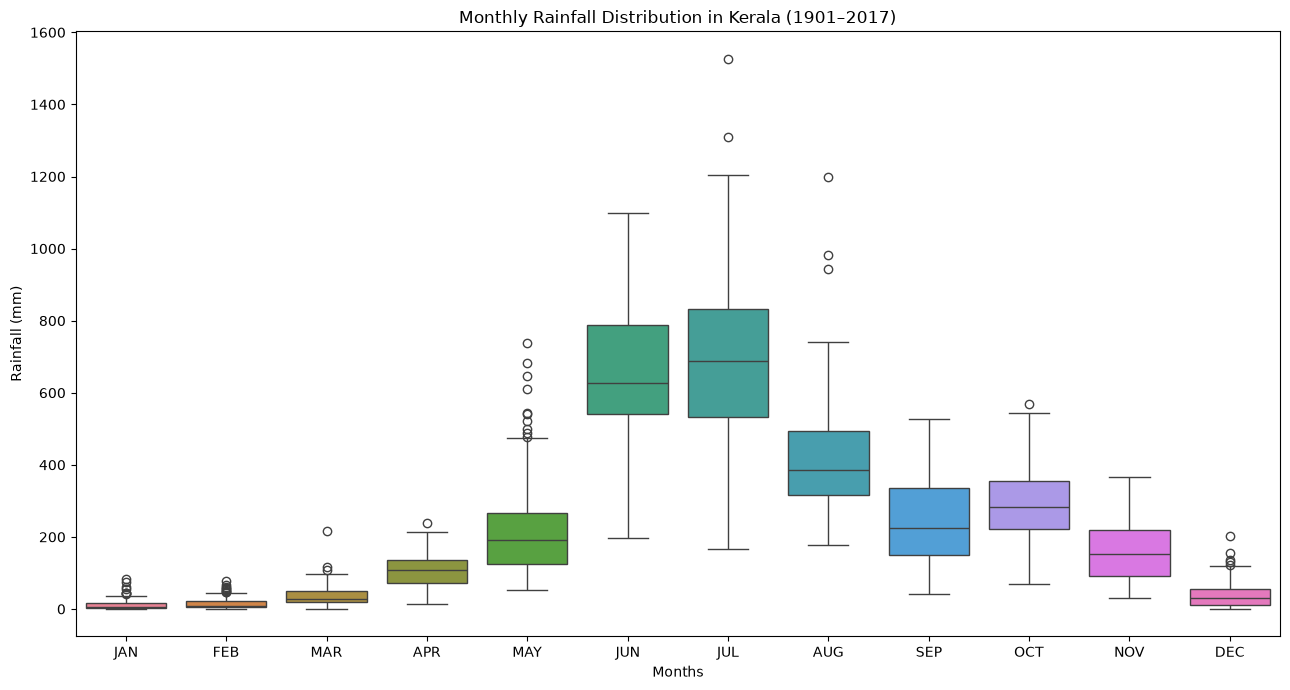

In [10]:
# Select monthly rainfall columns
monthly_data = df[months]

# Create boxplot
plt.figure(figsize=(13, 7))

sns.boxplot(data=monthly_data)

# Add title and labels
plt.title("Monthly Rainfall Distribution in Kerala (1901–2017)")
plt.xlabel("Months")
plt.ylabel("Rainfall (mm)")

plt.tight_layout()

# Save the figure
plt.savefig(
    "../figures/04_monthly_rainfall_distribution.png",
    dpi=300
)

# Display the graph
plt.show()